# Project 7 — Factor premia since 1963, and do factor ETFs deliver them?
Part A measures US equity factor returns July 1963 – August 2026 (the latest month in the
Kenneth French Data Library at the time of writing). Part B regresses five iShares factor
ETFs on the Fama-French five factors plus momentum.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT.parent)]

import numpy as np
import pandas as pd
from scipy import stats as st

from common import data as D
from common.plotting import PALETTE, setup, source
from src import factors as F

plt = setup()
DATA, FIG = ROOT / "data", ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.options.display.float_format = "{:.4f}".format
SRC_FF = "Source: Kenneth French Data Library (5 factors 2x3, momentum); author's calculations."

## Data

In [2]:
ff = D.french("F-F_Research_Data_5_Factors_2x3", DATA / "ff5_monthly.csv")
mom = D.french("F-F_Momentum_Factor", DATA / "ff_momentum_monthly.csv")
fac = ff.join(mom, how="inner")
fac.columns = [c.strip() for c in fac.columns]
FACTORS = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]
fac = fac.loc["1963-07":]
rec = D.fred("USREC", DATA / "fred_USREC.csv")["USREC"]
rec.index = rec.index + pd.offsets.MonthEnd(0)
cpi = D.fred("CPIAUCSL", DATA / "fred_CPIAUCSL.csv")["CPIAUCSL"]
cpi.index = cpi.index + pd.offsets.MonthEnd(0)
infl = cpi.pct_change(12, fill_method=None).rename("CPI YoY")
END = fac.index[-1]
print("Factors:", fac.index[0].date(), "to", END.date(), len(fac), "months")

Factors: 1963-07-31 to 2026-08-31 758 months


## A1. Premium, volatility, Sharpe, t-stat, drawdown, worst 5 years

In [3]:
A1 = pd.DataFrame({f: F.summary(fac[f]) for f in FACTORS}).T
A1

,Premium (ann.),Volatility,Sharpe,t-stat,Max drawdown,Worst 5y (ann.),Months
Mkt-RF,0.0722,0.1544,0.4676,3.7167,-0.5575,-0.1150,758.0000
SMB,0.0224,0.1046,0.2139,1.6997,-0.5645,-0.1090,758.0000
HML,0.0353,0.1029,0.3428,2.7248,-0.5778,-0.1074,758.0000
RMW,0.0302,0.0792,0.3808,3.0267,-0.4179,-0.0580,758.0000
CMA,0.0292,0.0718,0.4069,3.2339,-0.2763,-0.0385,758.0000
Mom,0.0716,0.1457,0.4911,3.9032,-0.5778,-0.1175,758.0000


## A2. Decade-by-decade annualized (compounded) returns

In [4]:
dec = (fac.index.year // 10) * 10
A2 = fac[FACTORS].groupby(dec).apply(lambda g: g.apply(F.ann_geo))
A2.index = [f"{d}s" + (" (from Jul 1963)" if d == 1960 else f" (to {END:%b %Y})" if d == 2020 else "")
            for d in A2.index]
A2

,Mkt-RF,SMB,HML,RMW,CMA,Mom
1960s (from Jul 1963),0.0392,0.0946,0.0211,0.0126,-0.0120,0.1048
1970s,-0.0027,0.0409,0.0765,-0.0075,0.0619,0.0933
1980s,0.0732,-0.0074,0.0559,0.0491,0.0552,0.0861
1990s,0.1251,-0.0253,-0.0035,0.0216,-0.0009,0.1373
2000s,-0.0307,0.0645,0.0738,0.0765,0.0650,-0.0200
2010s,0.1303,-0.0066,-0.0262,0.0123,0.0007,0.0262
2020s (to Aug 2026),0.1222,-0.0218,0.0097,0.0222,-0.0007,0.0154


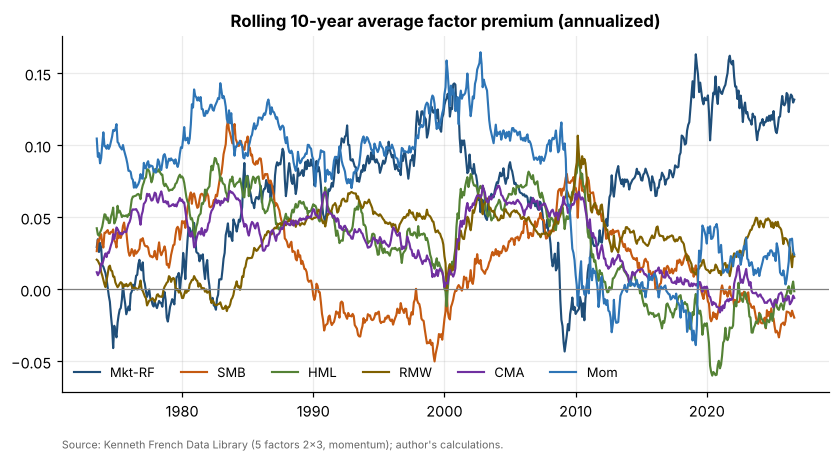

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for f in FACTORS:
    r10 = fac[f].rolling(120).mean() * 12
    ax.plot(r10.index, r10, lw=1.4, label=f)
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Rolling 10-year average factor premium (annualized)")
ax.legend(ncol=6, fontsize=8.5)
source(ax, SRC_FF)
fig.savefig(FIG / "fig_rolling_10y_premia.png"); plt.show()

## A3. Correlations: full sample and since 2010

In [6]:
C_full = fac[FACTORS].corr()
C_2010 = fac.loc["2010":, FACTORS].corr()
C_full.round(2), C_2010.round(2)

(        Mkt-RF     SMB     HML     RMW     CMA     Mom
 Mkt-RF  1.0000  0.2700 -0.2100 -0.1900 -0.3600 -0.1600
 SMB     0.2700  1.0000  0.0200 -0.3300 -0.0800 -0.0800
 HML    -0.2100  0.0200  1.0000  0.1000  0.6800 -0.1900
 RMW    -0.1900 -0.3300  0.1000  1.0000  0.0200  0.0600
 CMA    -0.3600 -0.0800  0.6800  0.0200  1.0000 -0.0200
 Mom    -0.1600 -0.0800 -0.1900  0.0600 -0.0200  1.0000,
         Mkt-RF     SMB     HML     RMW     CMA     Mom
 Mkt-RF  1.0000  0.3300  0.0300 -0.1400 -0.1600 -0.2500
 SMB     0.3300  1.0000  0.3300 -0.3100  0.0800 -0.2800
 HML     0.0300  0.3300  1.0000  0.1000  0.6300 -0.2600
 RMW    -0.1400 -0.3100  0.1000  1.0000  0.1900 -0.1100
 CMA    -0.1600  0.0800  0.6300  0.1900  1.0000 -0.0000
 Mom    -0.2500 -0.2800 -0.2600 -0.1100 -0.0000  1.0000)

## A4. Regimes: NBER recessions and inflation above 4%

In [7]:
# Each split uses every month with data for that split. FRED has no CPI for October 2025 (BLS did
# not publish it during the government shutdown), so that month is left out of the inflation split only.
reg_r = fac[FACTORS].join(rec).dropna()
reg_i = fac[FACTORS].join(infl).dropna()


def regime(col, mask_true, lab_true, lab_false):
    reg = reg_r if mask_true.name == "USREC" else reg_i
    a, b = reg.loc[mask_true, col], reg.loc[~mask_true, col]
    t = st.ttest_ind(a, b, equal_var=False)
    return {f"{lab_true} (avg/mo)": a.mean(), f"{lab_false} (avg/mo)": b.mean(),
            "Difference": a.mean() - b.mean(), "Welch t": t.statistic}


A4_rec = pd.DataFrame({f: regime(f, (reg_r["USREC"] == 1).rename("USREC"), "Recession", "Expansion") for f in FACTORS}).T
A4_inf = pd.DataFrame({f: regime(f, (reg_i["CPI YoY"] > 0.04).rename("CPI"), "CPI > 4%", "CPI <= 4%") for f in FACTORS}).T
n_rec, n_inf = int((reg_r["USREC"] == 1).sum()), int((reg_i["CPI YoY"] > 0.04).sum())
print(f"Recession months: {n_rec} of {len(reg_r)}; months with CPI YoY > 4%: {n_inf} of {len(reg_i)}")
A4_rec, A4_inf

Recession months: 85 of 758; months with CPI YoY > 4%: 255 of 757


(        Recession (avg/mo)  Expansion (avg/mo)  Difference  Welch t
 Mkt-RF             -0.0061              0.0076     -0.0137  -1.8126
 SMB                 0.0017              0.0019     -0.0002  -0.0503
 HML                 0.0029              0.0029      0.0000   0.0010
 RMW                 0.0035              0.0024      0.0011   0.4258
 CMA                 0.0073              0.0018      0.0054   1.9146
 Mom                 0.0004              0.0067     -0.0063  -0.8482,
         CPI > 4% (avg/mo)  CPI <= 4% (avg/mo)  Difference  Welch t
 Mkt-RF            -0.0003              0.0092     -0.0095  -2.5972
 SMB                0.0016              0.0020     -0.0005  -0.2072
 HML                0.0048              0.0021      0.0028   1.1952
 RMW                0.0028              0.0025      0.0003   0.1718
 CMA                0.0044              0.0015      0.0028   1.7132
 Mom                0.0083              0.0048      0.0036   1.1420)

## A5. Value's lost decade: HML January 2007 – December 2020, and afterwards

In [8]:
h = fac["HML"]
lost = h.loc["2007-01":"2020-12"]
after = h.loc["2021-01":]
w_lost = (1 + lost).cumprod()
lost_cum, after_cum = w_lost.iloc[-1] - 1, (1 + after).prod() - 1
# Share of the lost-decade loss recovered: wealth path 1 -> (1+lost_cum) -> (1+lost_cum)(1+after_cum)
recovered = ((1 + lost_cum) * (1 + after_cum) - (1 + lost_cum)) / (1 - (1 + lost_cum))
trough = w_lost.idxmin()
A5 = {"HML cum. return Jan 2007 - Dec 2020": lost_cum,
      "HML ann. return Jan 2007 - Dec 2020": F.ann_geo(lost),
      "HML peak-to-trough in the period": F.max_drawdown(lost),
      "Trough month": str(trough.date()),
      f"HML cum. return Jan 2021 - {END:%b %Y}": after_cum,
      "Share of 2007-2020 loss recovered": recovered,
      "HML ann. return Jul 1963 - Dec 2006": F.ann_geo(h.loc[:"2006-12"])}
A5

{'HML cum. return Jan 2007 - Dec 2020': np.float64(-0.5581771977369079),
 'HML ann. return Jan 2007 - Dec 2020': -0.05667665913904196,
 'HML peak-to-trough in the period': -0.5748812328369062,
 'Trough month': '2020-09-30',
 'HML cum. return Jan 2021 - Aug 2026': np.float64(0.5376549728672606),
 'Share of 2007-2020 loss recovered': np.float64(0.4255785218852065),
 'HML ann. return Jul 1963 - Dec 2006': 0.0537975047961996}

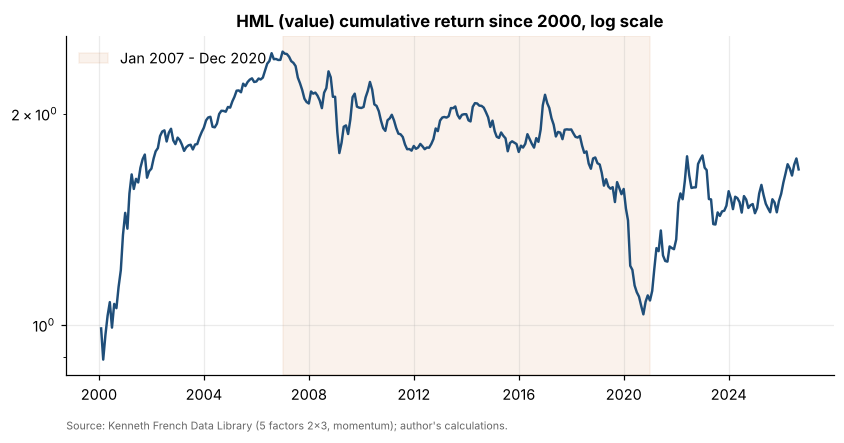

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
wh = (1 + h.loc["2000":]).cumprod()
ax.plot(wh.index, wh, color=PALETTE[0], lw=1.6)
ax.axvspan(pd.Timestamp("2007-01-01"), pd.Timestamp("2020-12-31"), color="#C55A11", alpha=0.08,
           label="Jan 2007 - Dec 2020")
ax.set_yscale("log"); ax.set_title("HML (value) cumulative return since 2000, log scale")
ax.legend(loc="upper left")
source(ax, SRC_FF)
fig.savefig(FIG / "fig_value_lost_decade.png"); plt.show()

## A6. Multi-factor blend: equal weight HML, RMW, CMA, Mom (monthly rebalanced)

In [10]:
blend = fac[["HML", "RMW", "CMA", "Mom"]].mean(axis=1).rename("Blend")
A6 = pd.DataFrame({c: {"Sharpe": F.summary(s)["Sharpe"], "Max drawdown": F.max_drawdown(s),
                       "Premium (ann.)": s.mean() * 12, "Volatility": s.std() * np.sqrt(12)}
                   for c, s in {**{f: fac[f] for f in ["HML", "RMW", "CMA", "Mom"]}, "Blend": blend}.items()}).T
A6

,Sharpe,Max drawdown,Premium (ann.),Volatility
HML,0.3428,-0.5778,0.0353,0.1029
RMW,0.3808,-0.4179,0.0302,0.0792
CMA,0.4069,-0.2763,0.0292,0.0718
Mom,0.4911,-0.5778,0.0716,0.1457
Blend,0.7412,-0.2180,0.0416,0.0561


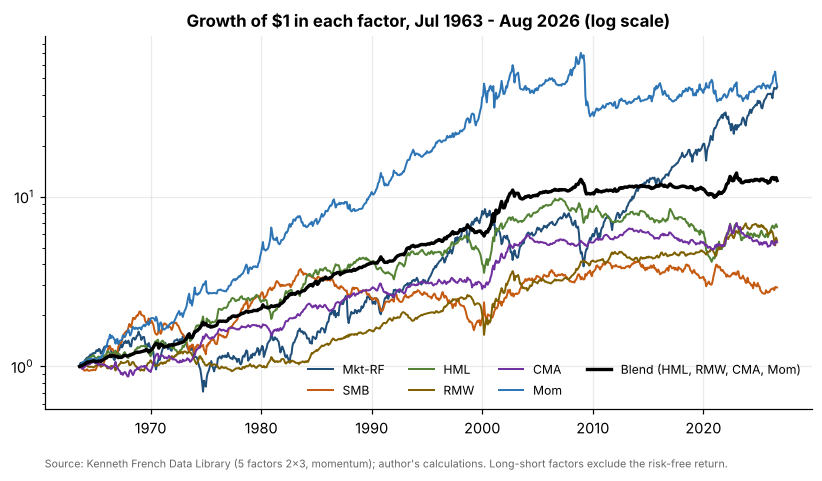

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.4))
for f in FACTORS:
    w = (1 + fac[f]).cumprod()
    ax.plot(w.index, w, lw=1.3, label=f)
wb = (1 + blend).cumprod()
ax.plot(wb.index, wb, color="black", lw=2.2, label="Blend (HML, RMW, CMA, Mom)")
ax.set_yscale("log"); ax.set_title(f"Growth of $1 in each factor, Jul 1963 - {END:%b %Y} (log scale)")
ax.legend(ncol=4, fontsize=8)
source(ax, SRC_FF + " Long-short factors exclude the risk-free return.")
fig.savefig(FIG / "fig_cumulative_factors.png"); plt.show()

## Part B. Do factor ETFs deliver their factor?

In [12]:
ETFS = {"MTUM": "Mom", "VLUE": "HML", "QUAL": "RMW", "SIZE": "SMB", "USMV": "Mkt-RF"}
px = D.prices(list(ETFS), "2013-07-01", "2026-10-01", DATA / "factor_etf_prices_daily.csv")
er = D.monthly_returns(px).loc["2013-08":"2026-09"]
er.to_csv(DATA / "factor_etf_monthly_returns.csv")
X = fac[FACTORS]
ex = er.sub(fac["RF"], axis=0).dropna()   # French RF; sample ends with the factor data
print("Regression sample:", ex.index[0].date(), "to", ex.index[-1].date(), len(ex), "months")

rows, models = {}, {}
for etf, target in ETFS.items():
    m = F.regress(ex[etf], X)
    models[etf] = m
    row = {"Alpha (ann.)": m.params["const"] * 12, "t(alpha)": m.tvalues["const"]}
    for f in FACTORS:
        row[f] = m.params[f]
        row[f"t({f})"] = m.tvalues[f]
    row["R2"] = m.rsquared
    rows[etf] = row
B2 = pd.DataFrame(rows).T
B2

Regression sample: 2013-08-31 to 2026-08-31 157 months


,Alpha (ann.),t(alpha),Mkt-RF,t(Mkt-RF),SMB,t(SMB),HML,t(HML),RMW,t(RMW),CMA,t(CMA),Mom,t(Mom),R2
MTUM,-0.0054,-0.3490,1.0969,29.2138,-0.1210,-2.2837,-0.0083,-0.1501,-0.2624,-2.3118,0.0785,0.8462,0.4480,8.4628,0.8923
VLUE,0.0017,0.1098,1.0503,15.6615,-0.0390,-0.3600,0.4184,7.3466,-0.2876,-1.5009,0.0754,1.1069,-0.0260,-0.4961,0.8651
QUAL,-0.0063,-0.7979,0.9765,48.9807,-0.0661,-2.3383,-0.0306,-0.9474,0.1730,4.1628,0.0282,0.5223,0.0213,0.8787,0.9602
SIZE,-0.0115,-1.1471,0.9538,41.2460,0.1443,3.8849,0.1218,2.7603,0.0703,1.5757,0.0413,0.6218,-0.0315,-1.0604,0.9432
USMV,-0.0057,-0.3604,0.7206,16.5138,-0.0745,-1.3454,-0.0302,-0.3628,0.2663,4.3184,0.1987,1.9554,0.0718,1.8581,0.7908


## Robustness: CAPM and Fama-French 3-factor alphas

In [13]:
rob = {}
for etf in ETFS:
    for name, cols in {"CAPM": ["Mkt-RF"], "FF3": ["Mkt-RF", "SMB", "HML"]}.items():
        mm = F.regress(ex[etf], X[cols])
        rob[(etf, name)] = {"Alpha (ann.)": mm.params["const"] * 12, "t(alpha)": mm.tvalues["const"],
                            "Beta": mm.params["Mkt-RF"], "R2": mm.rsquared}
B_rob = pd.DataFrame(rob).T
B_rob.to_csv(DATA / "B_robust_capm_ff3.csv")
B_rob

Alpha (ann.)  t(alpha)   Beta     R2
MTUM CAPM        0.0196    0.8993 0.9537 0.7252
     FF3         0.0121    0.5854 0.9800 0.7497
VLUE CAPM       -0.0083   -0.3101 1.0424 0.7678
     FF3        -0.0032   -0.2090 1.0379 0.8508
QUAL CAPM        0.0029    0.3218 0.9500 0.9449
     FF3        -0.0029   -0.3479 0.9758 0.9520
SIZE CAPM       -0.0183   -1.3299 0.9804 0.9110
     FF3        -0.0119   -1.1984 0.9596 0.9406
USMV CAPM        0.0100    0.5811 0.6557 0.7185
     FF3         0.0017    0.1015 0.6964 0.7448

## B3. Is the biggest loading the target factor?
For MTUM, VLUE, QUAL and SIZE, "biggest" means the largest loading among the five style
factors (SMB, HML, RMW, CMA, Mom), since every long-only equity fund has a market beta near 1.
For USMV the target is a low market beta: we test beta < 1.

In [14]:
STYLE = ["SMB", "HML", "RMW", "CMA", "Mom"]
B3 = {}
for etf, target in ETFS.items():
    m = models[etf]
    if etf == "USMV":
        b = m.params["Mkt-RF"]
        t_lt1 = (b - 1) / m.bse["Mkt-RF"]
        B3[etf] = {"Target": "Mkt-RF < 1", "Target loading": b, "t-stat": t_lt1,
                   "Largest style loading": max(STYLE, key=lambda f: abs(m.params[f])),
                   "Delivers target?": bool(b < 1 and t_lt1 < -2)}
    else:
        biggest = max(STYLE, key=lambda f: m.params[f])
        B3[etf] = {"Target": target, "Target loading": m.params[target], "t-stat": m.tvalues[target],
                   "Largest style loading": biggest,
                   "Delivers target?": bool(biggest == target and m.tvalues[target] > 2)}
B3 = pd.DataFrame(B3).T
B3

,Target,Target loading,t-stat,Largest style loading,Delivers target?
MTUM,Mom,0.4480,8.4628,Mom,True
VLUE,HML,0.4184,7.3466,HML,True
QUAL,RMW,0.1730,4.1628,RMW,True
SIZE,SMB,0.1443,3.8849,SMB,True
USMV,Mkt-RF < 1,0.7206,-6.4024,RMW,True


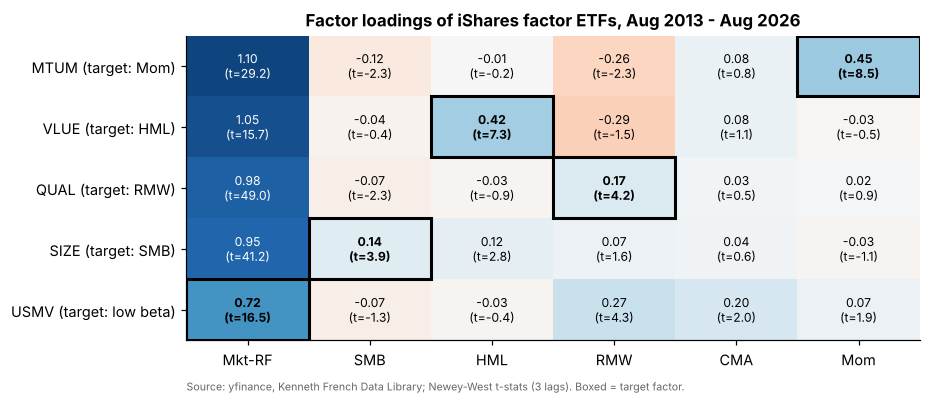

In [15]:
# Headline chart: table of loadings with t-stats as a heatmap
L = B2[FACTORS].astype(float)
T = B2[[f"t({f})" for f in FACTORS]].astype(float).values
fig, ax = plt.subplots(figsize=(8.6, 3.6))
im = ax.imshow(L.values, cmap="RdBu", vmin=-1.2, vmax=1.2, aspect="auto")
ax.set_xticks(range(len(FACTORS)), FACTORS); ax.set_yticks(range(len(L)), [f"{e} (target: {'low beta' if e == 'USMV' else ETFS[e]})" for e in L.index])
ax.grid(False)
for i in range(L.shape[0]):
    for j in range(L.shape[1]):
        tgt = (FACTORS[j] == ETFS[L.index[i]])
        ax.text(j, i, f"{L.values[i, j]:.2f}\n(t={T[i, j]:.1f})", ha="center", va="center", fontsize=8,
                fontweight="bold" if tgt else "normal",
                color="white" if abs(L.values[i, j]) > 0.75 else "black")
        if tgt:
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="black", lw=2))
ax.set_title(f"Factor loadings of iShares factor ETFs, {ex.index[0]:%b %Y} - {ex.index[-1]:%b %Y}")
source(ax, "Source: yfinance, Kenneth French Data Library; Newey-West t-stats (3 lags). Boxed = target factor.")
fig.savefig(FIG / "fig_etf_loadings.png"); plt.show()

## B4. Rolling 36-month loading on the target factor

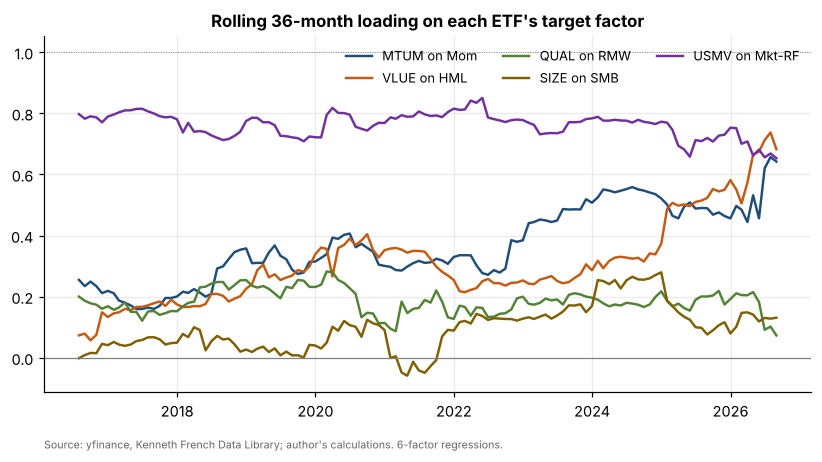

In [16]:
roll = {etf: F.rolling_beta(ex[etf], X, tgt, 36) for etf, tgt in ETFS.items()}
fig, ax = plt.subplots(figsize=(9, 4.2))
for etf, s in roll.items():
    ax.plot(s.index, s, lw=1.6, label=f"{etf} on {'Mkt-RF' if etf == 'USMV' else ETFS[etf]}")
ax.axhline(0, color="grey", lw=0.8); ax.axhline(1, color="grey", lw=0.6, ls=":")
ax.set_title("Rolling 36-month loading on each ETF's target factor")
ax.legend(ncol=3, fontsize=8.5)
source(ax, "Source: yfinance, Kenneth French Data Library; author's calculations. 6-factor regressions.")
fig.savefig(FIG / "fig_rolling_target_loading.png"); plt.show()
pd.DataFrame(roll).to_csv(DATA / "rolling_target_loadings.csv")

## ETF summary statistics (context)

In [17]:
etf_stats = pd.DataFrame({e: {"Ann. return": F.ann_geo(er[e].loc[:ex.index[-1]]),
                              "Volatility": er[e].loc[:ex.index[-1]].std() * np.sqrt(12),
                              "Sharpe": ex[e].mean() / ex[e].std() * np.sqrt(12)} for e in ETFS}).T
mkt = fac.loc[ex.index, "Mkt-RF"]
etf_stats.loc["Market (Mkt-RF + RF)"] = [F.ann_geo(mkt + fac.loc[ex.index, "RF"]),
                                        mkt.std() * np.sqrt(12), mkt.mean() / mkt.std() * np.sqrt(12)]
etf_stats

,Ann. return,Volatility,Sharpe
MTUM,0.1527,0.1672,0.8322
VLUE,0.1317,0.1775,0.6885
QUAL,0.1369,0.1458,0.8355
SIZE,0.1162,0.1530,0.6813
USMV,0.1083,0.1152,0.7985
Market (Mkt-RF + RF),0.1401,0.1491,0.8393


## Save

In [18]:
A1.to_csv(DATA / "A1_factor_summary.csv"); A2.to_csv(DATA / "A2_decades.csv")
C_full.to_csv(DATA / "A3_corr_full.csv"); C_2010.to_csv(DATA / "A3_corr_since2010.csv")
A4_rec.to_csv(DATA / "A4_recession.csv"); A4_inf.to_csv(DATA / "A4_inflation.csv")
A6.to_csv(DATA / "A6_blend.csv"); B2.to_csv(DATA / "B2_regressions.csv"); B3.to_csv(DATA / "B3_target_check.csv")
etf_stats.to_csv(DATA / "B_etf_stats.csv")
json.dump({"factor_start": str(fac.index[0].date()), "factor_end": str(END.date()), "n_factor": len(fac),
           "reg_start": str(ex.index[0].date()), "reg_end": str(ex.index[-1].date()), "n_reg": len(ex),
           "n_recession": n_rec, "n_infl": n_inf, "n_rec_sample": len(reg_r), "n_infl_sample": len(reg_i),
           "A5": {k: (float(v) if not isinstance(v, str) else v) for k, v in A5.items()}},
          open(DATA / "meta.json", "w"), indent=2)